# Hands-on 3: Regresión polinomial en Machine Learning
### Tutorial paso a paso con Python y scikit-learn (polinomio de grado n > 3)


**Alumno:** Antonio Valenzuela

---
**Objetivo.** Ajustar una curva polinomial de grado *n > 3* con el regresor de **mínimos cuadrados (least squares)**. Recorro cada etapa del pipeline de Machine Learning: recolección de datos, análisis, scatter plot, modelado, selección del grado y evaluación con métricas.

**Dataset.** Tomé los datos del ejemplo de Six-Sigma-Material.com sobre regresión (https://www.six-sigma-material.com/Regression.html). Un Black Belt de Six Sigma estudia la relación entre el **tamaño de lote** (*Batch Size*, la variable de entrada $x$) y la **eficiencia de la máquina** (*Machine Efficiency*, en %, la variable de salida $y$). Se corrió el mismo número de parte, en la misma máquina, con el mismo operador y condiciones similares.

La página publica la tabla como imagen, así que transcribí los 26 registros al archivo **`batch_efficiency.csv`**

## 1. Fundamentos teóricos

### 1.1 Regresión polinomial
Es regresión lineal sobre las columnas $x, x^2, \dots, x^n$. La curva no es lineal en $x$, pero el modelo sí es lineal en los parámetros $\beta$:

$$\hat{y} = \beta_0 + \beta_1 x + \beta_2 x^2 + \dots + \beta_n x^n$$

### 1.2 Mínimos cuadrados
Los coeficientes minimizan la suma de los residuales al cuadrado:

$$J(\boldsymbol\beta)=\sum_{i=1}^{m}\Big(y_i-\sum_{j=0}^{n}\beta_j x_i^{\,j}\Big)^2$$

### 1.3 Grado y rango
Un grado bajo subajusta y uno muy alto sobreajusta, así que el grado se elige con validación cruzada. El modelo sólo es válido dentro del rango observado de $x$ (25 a 115 unidades por lote).

## 2. Modelo matemático

Con la matriz de diseño (Vandermonde) $\mathbf{X}\in\mathbb{R}^{m\times(n+1)}$, con filas $[1, x_i, x_i^2, \dots, x_i^n]$, el modelo es $\hat{\mathbf y}=\mathbf X\boldsymbol\beta$. Al derivar el costo e igualar a cero se obtienen las ecuaciones normales:

$$\boxed{\mathbf X^\top\mathbf X\,\boldsymbol\beta=\mathbf X^\top\mathbf y}\qquad\Longrightarrow\qquad\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$$

Con $x$ entre 25 y 115, $\mathbf X^\top\mathbf X$ queda mal condicionada. Por eso se estandariza $x$ y se usa `np.linalg.lstsq` (lo que hace `LinearRegression`) en lugar de invertir la matriz.

Métricas usadas: $R^2 = 1-\frac{SS_{error}}{SS_{total}}$ y $R^2_{aj}=1-(1-R^2)\frac{m-1}{m-n-1}$.

### 3.0 Importación de librerías

In [ ]:
import numpy as np                                   # cálculo numérico y álgebra lineal
import pandas as pd                                  # lectura del CSV y manejo del dataset
import matplotlib.pyplot as plt                      # gráficas
from sklearn.model_selection import train_test_split # división entrenamiento / prueba
from sklearn.model_selection import LeaveOneOut, cross_val_predict  # validación cruzada leave-one-out
from sklearn.preprocessing import PolynomialFeatures # genera las columnas x, x^2, ..., x^n
from sklearn.preprocessing import StandardScaler     # estandariza x para mejorar el condicionamiento
from sklearn.linear_model import LinearRegression    # regresor de mínimos cuadrados ordinarios (OLS)
from sklearn.pipeline import Pipeline                # encadena escalado -> polinomio -> regresión
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # métricas

plt.rcParams["figure.figsize"] = (9, 5)              # tamaño por defecto de las figuras

### 3.1 Recolección de datos (importación del CSV)
El archivo `batch_efficiency.csv` contiene los 26 registros de la tabla publicada en la fuente, con dos columnas:
`batch_size` (piezas por lote) y `machine_efficiency` (%). La celda lo lee directamente desde el repositorio del curso

In [ ]:
ARCHIVO = "https://raw.githubusercontent.com/Antonio-valenzuela/Machine-Learning-2026B/refs/heads/main/pr%C3%A1ctica%203/batch_efficiency.csv"   # CSV publicado en el repositorio del curso (no hace falta subirlo)

df = pd.read_csv(ARCHIVO)                            # importa el dataset directamente desde la URL
df.head(10)                                          # muestra las primeras 10 filas

,batch_size,machine_efficiency
0,108,95
1,115,96
2,106,95
3,97,97
4,95,93
5,91,94
6,97,95
7,83,93
8,83,92
9,78,86


### 3.2 Descripción y análisis del dataset

In [ ]:
print("Dimensiones (filas, columnas):", df.shape)    # 26 observaciones, 2 variables
print("\nTipos de datos:")
print(df.dtypes)                                     # ambas columnas son numéricas
print("\nValores nulos por columna:")
print(df.isnull().sum())                             # 0 nulos: no se requiere imputación

Dimensiones (filas, columnas): (26, 2)

Tipos de datos:
batch_size            int64
machine_efficiency    int64
dtype: object

Valores nulos por columna:
batch_size            0
machine_efficiency    0
dtype: int64


In [ ]:
df.describe().T                                      # media, desviación estándar, mínimo, cuartiles y máximo

,count,mean,std,min,25%,50%,75%,max
batch_size,26.0,75.230769,27.626520,25.0,54.5,82.0,96.50,115.0
machine_efficiency,26.0,82.653846,14.672266,55.0,70.0,90.5,94.75,97.0


In [ ]:
repetidos = df["batch_size"].value_counts()          # cuántas veces se probó cada tamaño de lote
print("Tamaños de lote probados más de una vez:")
print(repetidos[repetidos > 1])                      # réplicas: mismo x con distinta y (variación natural)

r = df["batch_size"].corr(df["machine_efficiency"])  # correlación lineal de Pearson
print(f"\nCorrelación de Pearson: {r:.4f}")          # relación positiva fuerte
print("Rango de inferencia de x:", df.batch_size.min(), "a", df.batch_size.max())  # 25 a 115

Tamaños de lote probados más de una vez:
batch_size
115    2
97     2
83     2
78     2
Name: count, dtype: int64

Correlación de Pearson: 0.9643
Rango de inferencia de x: 25 a 115


Hay 26 registros sin nulos. La eficiencia sube rápido entre lotes de 40 a 80 piezas y después se aplana cerca de 95 %

### 3.3 Visualización: scatter plot

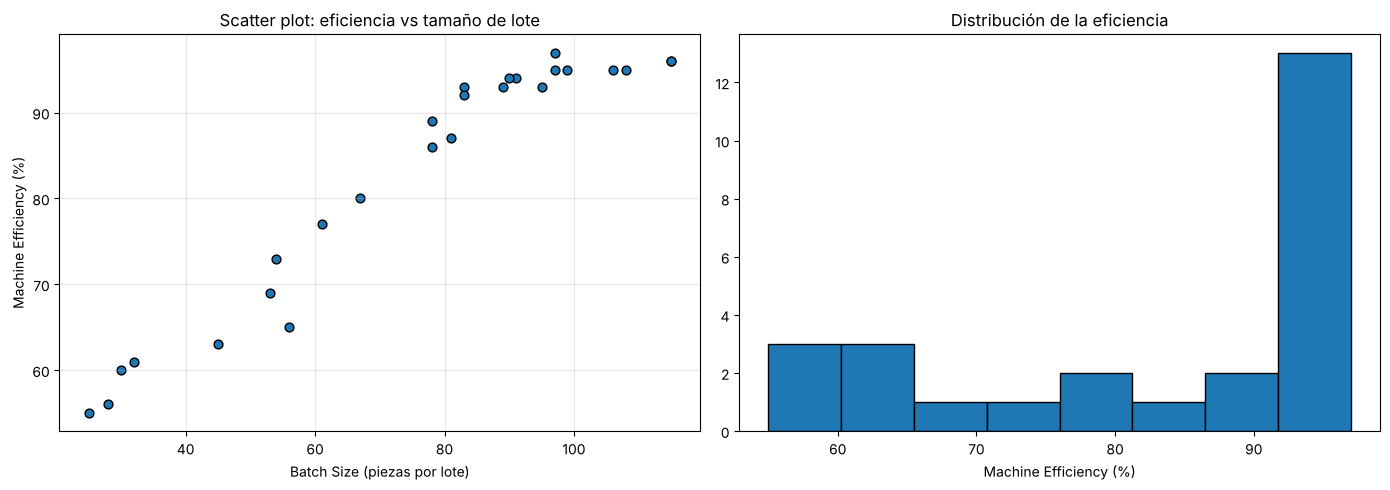

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))        # dos gráficas lado a lado

ax[0].scatter(df.batch_size, df.machine_efficiency, s=40, edgecolor="k")  # scatter plot de los datos
ax[0].set_xlabel("Batch Size (piezas por lote)")     # etiqueta eje x
ax[0].set_ylabel("Machine Efficiency (%)")           # etiqueta eje y
ax[0].set_title("Scatter plot: eficiencia vs tamaño de lote")
ax[0].grid(alpha=.3)                                 # cuadrícula suave

ax[1].hist(df.machine_efficiency, bins=8, edgecolor="k")  # distribución de la variable respuesta
ax[1].set_xlabel("Machine Efficiency (%)")
ax[1].set_title("Distribución de la eficiencia")
plt.tight_layout()                                   # ajusta márgenes
plt.show()                                           # muestra la figura

### 3.4 Validación del dataset contra la fuente
La página reporta estos valores para el ajuste cúbico con los 26 datos:

$$Y = 65.07 - 0.8923X + 0.02565X^2 - 0.000136X^3,\qquad R^2=\frac{SS_{Regression}}{SS_{Total}}=\frac{5268.98}{5381.88}=97.9\%$$

y una predicción de **78.09 %** para un lote de 65.

In [ ]:
x = df["batch_size"].values                          # vector x (26,)
y = df["machine_efficiency"].values                  # vector y (26,)

coef3 = np.polyfit(x, y, deg=3)[::-1]                # ajuste cúbico por mínimos cuadrados; [::-1] -> β0, β1, β2, β3
y3 = np.polyval(coef3[::-1], x)                      # valores ajustados por la cúbica
ss_tot = ((y - y.mean()) ** 2).sum()                 # SS total: variación de y alrededor de su media
ss_err = ((y - y3) ** 2).sum()                       # SS error: suma de residuales al cuadrado
ss_reg = ss_tot - ss_err                             # SS regresión: variación explicada

print("Coeficientes cúbica:", [f"{c:.6g}" for c in coef3])  # comparar con 65.07, -0.8923, 0.02565, -0.000136
print(f"SS regression = {ss_reg:.2f}   SS total = {ss_tot:.2f}")  # comparar con 5268.98 y 5381.88
print(f"R² = {ss_reg/ss_tot:.4f}")                   # comparar con 0.979
print(f"Predicción para lote 65: {np.polyval(coef3[::-1], 65):.2f} %")  # comparar con 78.09 %

Coeficientes cúbica: ['65.074', '-0.892299', '0.0256497', '-0.000136017']
SS regression = 5268.98   SS total = 5381.88
R² = 0.9790
Predicción para lote 65: 78.09 %


### 3.5 Ajuste analítico con las ecuaciones normales
Se aplica $\hat{\boldsymbol\beta}=(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$ a un polinomio de grado 4. Se usa
$z=(x-\mu)/\sigma$ en lugar de $x$ para evitar el mal condicionamiento numérico.

In [ ]:
n = 4                                                # grado para la demostración (n > 3)
mu, sigma = x.mean(), x.std()                        # media y desviación estándar de x
z = (x - mu) / sigma                                 # x estandarizada

Xd = np.vander(z, N=n + 1, increasing=True)          # matriz de Vandermonde: columnas 1, z, z^2, z^3, z^4
XtX = Xd.T @ Xd                                      # producto X^T X  (5 x 5)
Xty = Xd.T @ y                                       # producto X^T y  (5,)
beta_normal = np.linalg.solve(XtX, Xty)              # resuelve X^T X β = X^T y

for j, b in enumerate(beta_normal):                  # imprime cada coeficiente
    print(f"β{j} = {b: .4f}")

β0 =  85.6297
β1 =  17.5244
β2 = -5.1078
β3 = -2.4073
β4 =  0.5389


In [ ]:
Xd_crudo = np.vander(x.astype(float), N=n + 1, increasing=True)  # misma matriz pero con x sin escalar
print(f"Número de condición SIN escalar: {np.linalg.cond(Xd_crudo.T @ Xd_crudo):.2e}")  # enorme -> inestable
print(f"Número de condición CON escalar: {np.linalg.cond(XtX):.2e}")                   # pequeño -> estable

Número de condición SIN escalar: 1.61e+19
Número de condición CON escalar: 5.37e+02


### 3.6 El mismo modelo con scikit-learn (`Pipeline`)

| Clase | Rol | Atributos / parámetros clave |
|---|---|---|
| `StandardScaler` | Estandariza $x$ → $z$ | `mean_`, `scale_` |
| `PolynomialFeatures(degree=n, include_bias=False)` | Genera $z,\dots,z^n$ | `degree`, `get_feature_names_out()` |
| `LinearRegression()` | Mínimos cuadrados | `coef_` ($\beta_1..\beta_n$), `intercept_` ($\beta_0$) |
| `Pipeline` | Encadena pasos y evita fuga de datos | `named_steps` |

`include_bias=False` porque `LinearRegression` ya estima $\beta_0$. scikit-learn exige que $X$ sea 2D, por eso se usa
`df[["batch_size"]]`.

In [ ]:
X = df[["batch_size"]].values                        # matriz de features 2D (26 x 1)

def modelo_polinomial(grado):                        # construye el pipeline para cualquier grado
    return Pipeline([
        ("escala", StandardScaler()),                # paso 1: z = (x - media) / desviación
        ("poli", PolynomialFeatures(degree=grado, include_bias=False)),  # paso 2: z, z^2, ..., z^grado
        ("ols", LinearRegression()),                 # paso 3: mínimos cuadrados
    ])

m4 = modelo_polinomial(4).fit(X, y)                  # entrena el pipeline de grado 4 con todos los datos
ols = m4.named_steps["ols"]                          # regresor entrenado
beta_sklearn = np.r_[ols.intercept_, ols.coef_]      # [β0, β1, ..., β4]
print("Features:", m4.named_steps["poli"].get_feature_names_out(["z"]))
print("β scikit-learn:     ", np.round(beta_sklearn, 4))
print("β ecuac. normales:  ", np.round(beta_normal, 4))
print("¿Coinciden?", np.allclose(beta_sklearn, beta_normal))  # True: es el mismo estimador

Features: ['z' 'z^2' 'z^3' 'z^4']
β scikit-learn:      [85.6297 17.5244 -5.1078 -2.4073  0.5389]
β ecuac. normales:   [85.6297 17.5244 -5.1078 -2.4073  0.5389]
¿Coinciden? True


### 3.7 Selección del grado *n* con validación cruzada
Con sólo 26 datos, una única partición de prueba es muy pequeña y su resultado depende de qué puntos caen en ella.
Por eso el grado se elige con **validación cruzada *leave-one-out* (LOOCV)**: se entrena 26 veces, cada vez dejando
fuera un punto, y se mide el error al predecir ese punto. También se calculan $R^2$ y $R^2$ ajustado sobre todos los
datos.

In [ ]:
m_obs = len(y)                                       # número de observaciones
filas = []                                           # resultados por grado
for g in range(1, 8):                                # grados candidatos 1 a 7
    pred_loo = cross_val_predict(modelo_polinomial(g), X, y, cv=LeaveOneOut())  # predicción de cada punto excluido
    r2 = r2_score(y, modelo_polinomial(g).fit(X, y).predict(X))  # R² del ajuste con todos los datos
    filas.append({"grado": g,
                  "RMSE_LOOCV": np.sqrt(mean_squared_error(y, pred_loo)),  # error de generalización
                  "R2": r2,
                  "R2_ajustado": 1 - (1 - r2) * (m_obs - 1) / (m_obs - g - 1)})  # penaliza términos extra
tabla = pd.DataFrame(filas).round(4)
tabla

,grado,RMSE_LOOCV,R2,R2_ajustado
0,1,4.1324,0.9299,0.9270
1,2,3.4390,0.9547,0.9508
2,3,2.4919,0.9790,0.9762
3,4,2.6142,0.9795,0.9756
4,5,2.2735,0.9838,0.9798
5,6,2.3385,0.9841,0.9791
6,7,2.7409,0.9844,0.9783


Grado elegido: n = 5


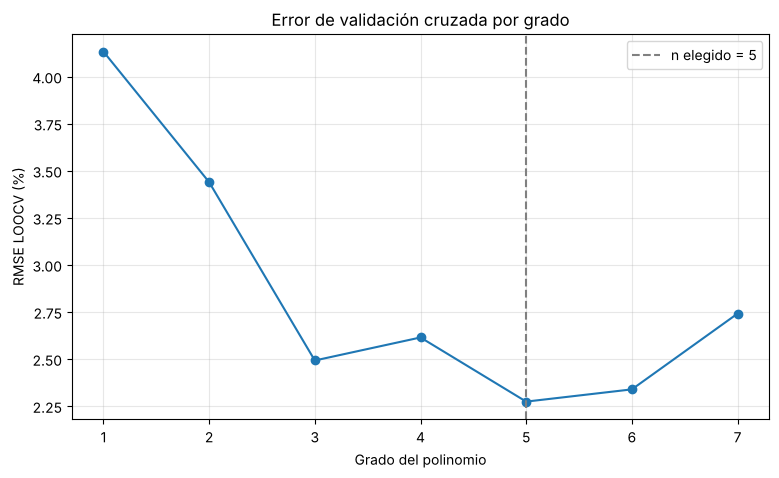

In [ ]:
candidatos = tabla[tabla.grado > 3]                  # el enunciado exige n > 3
n_opt = int(candidatos.loc[candidatos.RMSE_LOOCV.idxmin(), "grado"])  # menor error LOOCV
print("Grado elegido: n =", n_opt)

plt.plot(tabla.grado, tabla.RMSE_LOOCV, "o-")        # error de validación por grado
plt.axvline(n_opt, ls="--", c="gray", label=f"n elegido = {n_opt}")
plt.xlabel("Grado del polinomio"); plt.ylabel("RMSE LOOCV (%)")
plt.title("Error de validación cruzada por grado"); plt.legend(); plt.grid(alpha=.3)
plt.show()

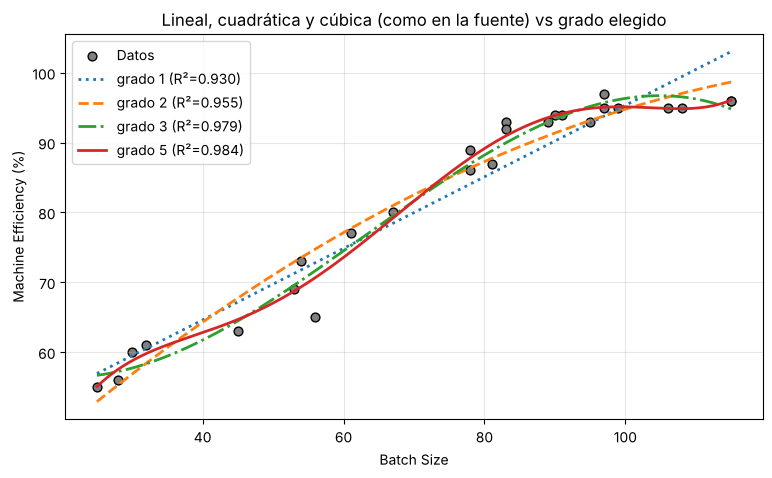

In [ ]:
x_plot = np.linspace(25, 115, 300).reshape(-1, 1)    # malla dentro del rango de inferencia
plt.scatter(X, y, s=40, c="gray", edgecolor="k", label="Datos")
for g, estilo in [(1, ":"), (2, "--"), (3, "-."), (n_opt, "-")]:  # grados a comparar
    mdl = modelo_polinomial(g).fit(X, y)             # ajusta cada grado
    plt.plot(x_plot, mdl.predict(x_plot), estilo, lw=2,
             label=f"grado {g} (R²={r2_score(y, mdl.predict(X)):.3f})")
plt.xlabel("Batch Size"); plt.ylabel("Machine Efficiency (%)")
plt.title("Lineal, cuadrática y cúbica (como en la fuente) vs grado elegido")
plt.legend(); plt.grid(alpha=.3); plt.show()

### 3.8 Entrenamiento del modelo (partición entrenamiento / prueba)
Además de la validación cruzada, se separa un 25 % de los datos como prueba para evaluar el modelo en registros
que no vio durante el entrenamiento.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split( # divide aleatoriamente
    X, y, test_size=0.25, random_state=42)           # 19 para entrenar, 7 para probar
print("Entrenamiento:", X_train.shape, " Prueba:", X_test.shape)
print("Lotes en prueba:", sorted(X_test.ravel()))     # todos dentro del rango 25–115

modelo = modelo_polinomial(n_opt).fit(X_train, y_train)  # entrena el grado elegido

Entrenamiento: (19, 1)  Prueba: (7, 1)
Lotes en prueba: [np.int64(53), np.int64(67), np.int64(78), np.int64(81), np.int64(83), np.int64(90), np.int64(108)]


### 3.9 Evaluación de la técnica (métricas)

In [ ]:
def metricas(y_real, y_est):                         # calcula MAE, RMSE y R²
    return {"MAE": mean_absolute_error(y_real, y_est),
            "RMSE": np.sqrt(mean_squared_error(y_real, y_est)),
            "R2": r2_score(y_real, y_est)}

resultados = pd.DataFrame({
    "Entrenamiento": metricas(y_train, modelo.predict(X_train)),  # qué tan bien ajusta lo que vio
    "Prueba": metricas(y_test, modelo.predict(X_test)),           # qué tan bien generaliza
    "LOOCV (26 datos)": metricas(y, cross_val_predict(modelo_polinomial(n_opt), X, y, cv=LeaveOneOut())),
}).round(4)
resultados

,Entrenamiento,Prueba,LOOCV (26 datos)
MAE,1.3522,1.2318,1.5892
RMSE,1.9341,1.7954,2.2735
R2,0.9851,0.9555,0.9750


In [ ]:
comp = {}                                            # comparación de grados en la misma partición de prueba
for g in [1, 2, 3, 4, n_opt]:
    mdl = modelo_polinomial(g).fit(X_train, y_train) # entrena con la misma partición
    comp[f"grado {g}"] = metricas(y_test, mdl.predict(X_test))
pd.DataFrame(comp).T.round(4)

,MAE,RMSE,R2
grado 1,3.1297,3.4389,0.8367
grado 2,2.0513,2.4266,0.9187
grado 3,1.1892,1.3395,0.9752
grado 4,1.1809,1.3787,0.9737
grado 5,1.2318,1.7954,0.9555


En prueba (7 puntos) las diferencias entre los grados 3 a 5 son pequeñas. Con LOOCV, que usa los 26 puntos, el grado elegido tiene el menor error entre los grados mayores a 3.

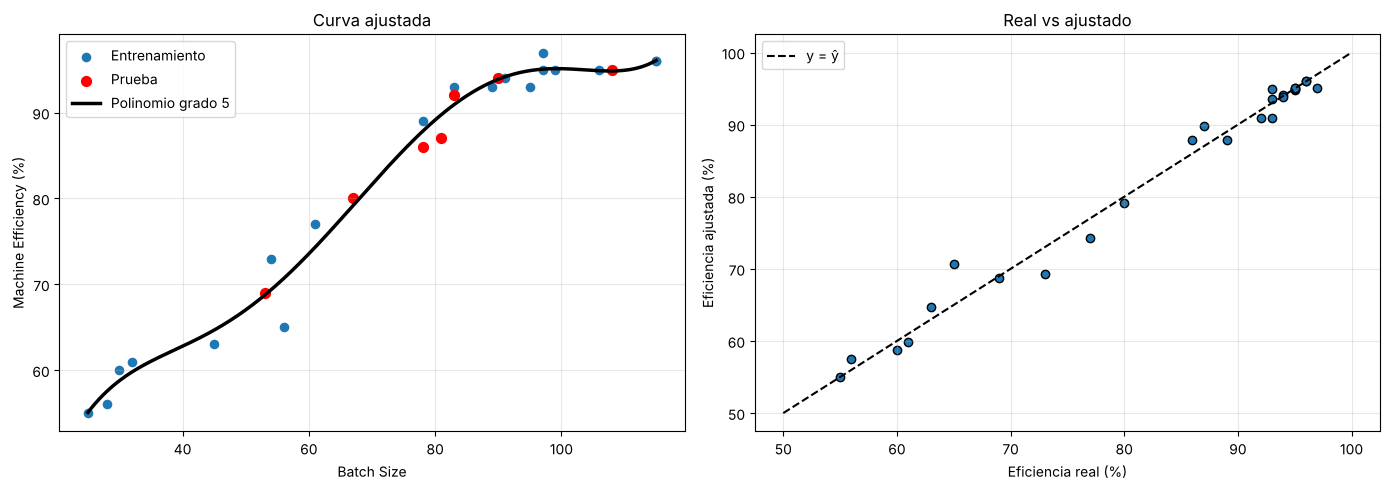

z = (BatchSize - 75.2308) / 27.0900
ŷ = 85.8026 +20.4526·z^1 -6.9029·z^2 -7.6918·z^3 +1.6622·z^4 +1.7228·z^5


In [ ]:
modelo_final = modelo_polinomial(n_opt).fit(X, y)    # modelo final entrenado con los 26 datos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(X_train, y_train, s=35, label="Entrenamiento")
ax[0].scatter(X_test, y_test, s=50, c="red", label="Prueba")
ax[0].plot(x_plot, modelo_final.predict(x_plot), "k", lw=2.5, label=f"Polinomio grado {n_opt}")
ax[0].set_xlabel("Batch Size"); ax[0].set_ylabel("Machine Efficiency (%)")
ax[0].set_title("Curva ajustada"); ax[0].legend(); ax[0].grid(alpha=.3)

y_hat = modelo_final.predict(X)                      # valores ajustados
ax[1].scatter(y, y_hat, edgecolor="k")               # real vs ajustado
ax[1].plot([50, 100], [50, 100], "k--", label="y = ŷ")
ax[1].set_xlabel("Eficiencia real (%)"); ax[1].set_ylabel("Eficiencia ajustada (%)")
ax[1].set_title("Real vs ajustado"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

esc, ols = modelo_final.named_steps["escala"], modelo_final.named_steps["ols"]
print(f"z = (BatchSize - {esc.mean_[0]:.4f}) / {esc.scale_[0]:.4f}")  # transformación aplicada
print("ŷ =", f"{ols.intercept_:.4f}", " ".join(f"{b:+.4f}·z^{j}" for j, b in enumerate(ols.coef_, 1)))

### 3.10 Análisis de residuales

Media de residuales: 0.0000
Desv. estándar de residuales: 1.8291 %


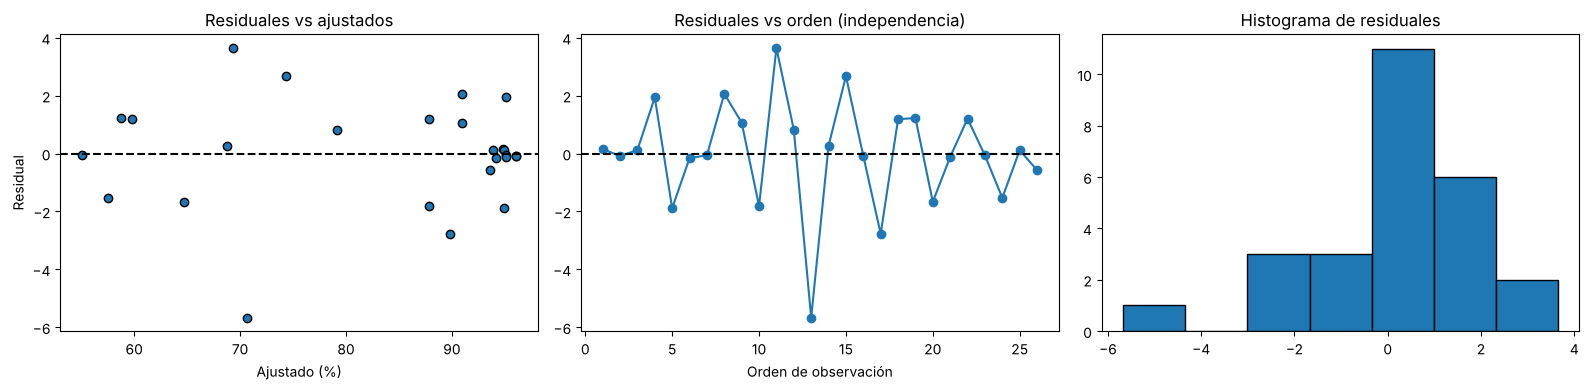

In [ ]:
residuales = y - y_hat                               # e_i = y_i - ŷ_i (modelo final)
print(f"Media de residuales: {residuales.mean():.4f}")      # ~0
print(f"Desv. estándar de residuales: {residuales.std():.4f} %")

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(y_hat, residuales, edgecolor="k")      # residuales vs ajustados
ax[0].axhline(0, c="k", ls="--"); ax[0].set_title("Residuales vs ajustados")
ax[0].set_xlabel("Ajustado (%)"); ax[0].set_ylabel("Residual")
ax[1].plot(range(1, len(residuales) + 1), residuales, "o-")  # residuales en orden de registro
ax[1].axhline(0, c="k", ls="--"); ax[1].set_title("Residuales vs orden (independencia)")
ax[1].set_xlabel("Orden de observación")
ax[2].hist(residuales, bins=7, edgecolor="k")        # forma de la distribución
ax[2].set_title("Histograma de residuales")
plt.tight_layout(); plt.show()

### 3.11 Predicción y rango de inferencia
Como en la fuente, se estima la eficiencia para un lote de **65 piezas**. La fuente plantea ese tamaño como el EOQ fijado por Finanzas. También se muestra qué pasa al salir del rango de 25 a 115.

Grado 5: eficiencia estimada para lote 65 = 77.53 %
Cúbica de la fuente: 78.09 %


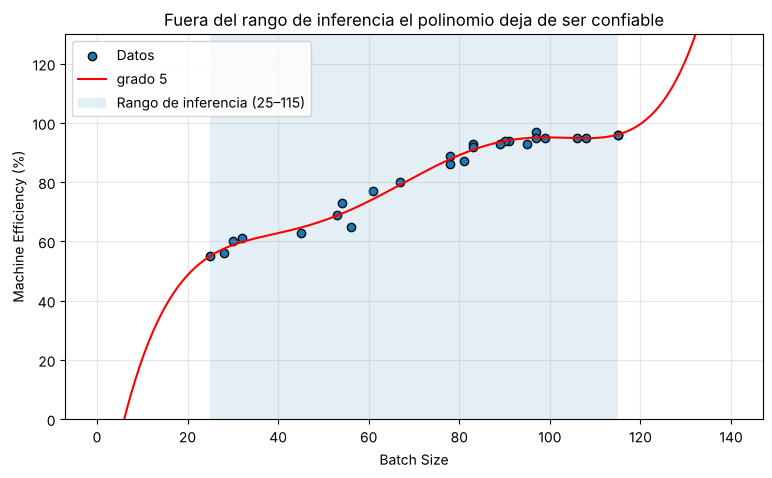

In [ ]:
lote = np.array([[65]])                              # tamaño de lote a consultar
print(f"Grado {n_opt}: eficiencia estimada para lote 65 = {modelo_final.predict(lote)[0]:.2f} %")
print(f"Cúbica de la fuente: {65.07 - 0.8923*65 + 0.02565*65**2 - 0.000136*65**3:.2f} %")  # 78.09 % reportado

x_ext = np.linspace(0, 140, 300).reshape(-1, 1)      # rango extendido fuera de 25–115
plt.scatter(X, y, edgecolor="k", label="Datos")
plt.plot(x_ext, modelo_final.predict(x_ext), "r", label=f"grado {n_opt}")
plt.axvspan(25, 115, alpha=.12, label="Rango de inferencia (25–115)")
plt.ylim(0, 130); plt.xlabel("Batch Size"); plt.ylabel("Machine Efficiency (%)")
plt.title("Fuera del rango de inferencia el polinomio deja de ser confiable")
plt.legend(); plt.grid(alpha=.3); plt.show()

## 4. Conclusiones
- Con el dataset de Six-Sigma-Material, la cúbica reproduce la ecuación y el $R^2$ de 97.9 % publicados por la fuente
- La solución analítica $(\mathbf X^\top\mathbf X)^{-1}\mathbf X^\top\mathbf y$ coincide con `LinearRegression`.
- LOOCV elige un grado mayor a 3 con una ganancia pequeña sobre la cúbica. El modelo sólo debe usarse entre 25 y 115 piezas.

**Referencias:** [Six-Sigma-Material: Regression](https://www.six-sigma-material.com/Regression.html); documentación de scikit-learn.